# Detección de anomalías para identificación de fraude en comercio electrónico

* El objetivo de este trabajo es poder abordar uno de los casos de uso más habituales en la detección de anomalías: la identificación de fraude.
* Para ello, nos apoyaremos en un conjunto de datos sintético sobre transacciones financieras, que simula la complejidad y riqueza de estos datos (https://www.kaggle.com/datasets/shriyashjagtap/fraudulent-e-commerce-transactions/data)
* En este contexto, el fraude hace referencia a causísticas como el uso de datos de tarjeta de crédito o débito obtenidos ilegalmente (por phishing, malware o filtraciones de datos) para realizar una compra en línea.
* El enfoque de detección de anomalías basado en el uso de soluciones no supervisadas es clave debido a que las tácticas fraudulentas evolucionan constantemente.
* Por ello, trabajaremos distintos tipos de enfoques de detección de anomalías en este contexto: puntuales, contextuales y colectivas, de cara a ver qué enfoque es el más efectivo.


### Descripción de Campos de Transacción

---

#### Identificadores Únicos

* **Transaction ID (ID de Transacción):** Un identificador único para cada transacción.
* **Customer ID (ID de Cliente):** Un identificador único para cada cliente.

---

#### Detalles Financieros y Temporales

* **Transaction Amount (Monto de la Transacción):** La cantidad total de dinero intercambiada en la transacción.
* **Transaction Date (Fecha de Transacción):** La fecha y hora en que tuvo lugar la transacción.
* **Transaction Hour (Hora de la Transacción):** La hora del día en que ocurrió la transacción.

---

#### Detalles del Producto y Pago

* **Payment Method (Método de Pago):** El método utilizado para completar la transacción (por ejemplo, tarjeta de crédito, PayPal, etc.).
* **Product Category (Categoría de Producto):** La categoría del producto involucrado en la transacción.
* **Quantity (Cantidad):** El número de productos involucrados en la transacción.

---

#### Información del Cliente y Envío

* **Customer Age (Edad del Cliente):** La edad del cliente que realiza la transacción.
* **Customer Location (Ubicación del Cliente):** La ubicación geográfica del cliente.
* **Shipping Address (Dirección de Envío):** La dirección donde se envió el producto.
* **Billing Address (Dirección de Facturación):** La dirección asociada con el método de pago.
* **Account Age Days (Antigüedad de la Cuenta en Días):** La antigüedad de la cuenta del cliente en días en el momento de la transacción.

---

#### Detalles Técnicos y Detección de Fraude

* **Device Used (Dispositivo Utilizado):** El tipo de dispositivo utilizado para realizar la transacción (por ejemplo, móvil, escritorio).
* **IP Address (Dirección IP):** La dirección IP del dispositivo utilizado para la transacción.
* **Is Fraudulent (Es Fraudulenta):** Un indicador binario de si la transacción es fraudulenta (1 para fraudulenta, 0 para legítima).

## 0. Carga de Librerías y Definir funciones comunes

In [1]:
# Instalar dependencias necesarias
import subprocess
import sys

def install_package(package):
    try:
        __import__(package)
        print(f"{package} ya está instalado")
    except ImportError:
        print(f"Instalando {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

# Instalar ruptures si no está disponible
install_package("ruptures")

Instalando ruptures...
  Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl (5.5 MB)
Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_arm64.whl (20.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ruptures]2/3 [ruptures]


In [14]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)
from sklearn.decomposition import PCA
import warnings
import os

# Configurar warnings y estilo de visualización
warnings.filterwarnings('ignore')
plt.style.use('default')
sns.set_palette("husl")

# Configurar semilla para reproducibilidad
np.random.seed(42)

print("Librerías importadas correctamente")

Librerías importadas correctamente


### 0.1. Funciones comunes

In [26]:
# Aqui puedes incluir tus funciones comunes para el código
from IPython.display import display, HTML

# Definir paleta de colores a usar
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
GRIS = '#8a8984'

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRIS, 'axes.labelcolor': '#52514e', 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'legend.frameon': False, 'lines.linewidth': 1.8,
    'axes.prop_cycle': plt.cycler(color=PALETTE),
})

# Definir formato tabla compatible con cualquier visor de notebooks (HTML nativo sin jinja2)
def show_table(df, fmt=None, default='.4f', index=True):
    """Muestra un DataFrame como tabla HTML estética con contraste explícito para temas claros y oscuros."""
    fmt = fmt or {}
    out = df.copy()
    for c in out.columns:
        f = fmt.get(c, default if pd.api.types.is_float_dtype(out[c]) else None)
        if f is not None:
            out[c] = out[c].map(lambda v, fmt_str=f: '—' if pd.isna(v) else format(v, fmt_str))
            
    html_tabla = out.to_html(index=index, border=0)
    estilo = """
    <style>
        .tabla-actividad {
            border-collapse: collapse;
            margin: 10px 0 18px 0;
            font-size: 0.92em;
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
            min-width: 420px;
            background-color: #ffffff;
            color: #1f2328;
            border-radius: 6px;
            overflow: hidden;
        }
        .tabla-actividad thead tr,
        .tabla-actividad thead th {
            background-color: #2a78d6 !important;
            color: #ffffff !important;
            text-align: left;
            font-weight: 600;
        }
        .tabla-actividad th, .tabla-actividad td {
            padding: 8px 13px;
            border-bottom: 1px solid #d8dee4;
        }
        .tabla-actividad tbody tr:nth-of-type(odd),
        .tabla-actividad tbody tr:nth-of-type(odd) th,
        .tabla-actividad tbody tr:nth-of-type(odd) td {
            background-color: #ffffff !important;
            color: #1f2328 !important;
        }
        .tabla-actividad tbody tr:nth-of-type(even),
        .tabla-actividad tbody tr:nth-of-type(even) th,
        .tabla-actividad tbody tr:nth-of-type(even) td {
            background-color: #f3f6fa !important;
            color: #1f2328 !important;
        }
        .tabla-actividad tbody tr:hover td,
        .tabla-actividad tbody tr:hover th {
            background-color: #e6effb !important;
            color: #0f1419 !important;
        }
    </style>
    """
    html_tabla = html_tabla.replace('<table class="dataframe">', '<table class="dataframe tabla-actividad">')
    display(HTML(estilo + html_tabla))

def titulo(texto):
    """Muestra un subtítulo en negrita compatible con cualquier visor."""
    display(HTML(f'<p style="font-weight: bold; font-size: 1.02em; margin: 12px 0 4px 0;">{texto}</p>'))

In [16]:
# Lista global para ir acumulando los resultados de todos los enfoques
RESULTADOS_EXPERIMENTOS = []

#Función de escalado
def escalar_datos(df, columnas, metodo='robust'):
    """
    Escala las variables numéricas seleccionadas.
    metodo: 'standard' (Z-score) o 'robust' (Mediana e IQR, resistente a outliers).
    """
    scaler = RobustScaler() if metodo == 'robust' else StandardScaler()
    X_scaled = scaler.fit_transform(df[columnas])
    return pd.DataFrame(X_scaled, columns=columnas, index=df.index), scaler

# Función para unificar etiquetas (0 = Normal, 1 = Anomalía)
def normalizar_predicciones(y_raw, tipo='sklearn'):
    """
    Convierte salidas heterogéneas a formato binario estándar (0: Normal, 1: Anomalía).
    tipo: 
      - 'sklearn': -1 es anomalía, 1 (o >=0 en DBSCAN) es normal.
      - 'booleano': True/1 es anomalía, False/0 es normal.
    """
    y_arr = np.asarray(y_raw)
    if tipo == 'sklearn':
        return np.where(y_arr == -1, 1, 0)
    return y_arr.astype(int)

# Función  de evaluación y registro comparativo
def evaluar_detector(nombre_modelo, enfoque, y_true, y_pred_bin, scores_anomalia=None, registrar=True):
    """
    Calcula métricas clave para datasets desbalanceados y opcionalmente las guarda
    en la tabla comparativa global.
    scores_anomalia: puntaje continuo donde MAYOR valor = MAYOR probabilidad de anomalía.
    """
    prec = precision_score(y_true, y_pred_bin, zero_division=0)
    rec = recall_score(y_true, y_pred_bin, zero_division=0)
    f1 = f1_score(y_true, y_pred_bin, zero_division=0)
    tasa_det = y_pred_bin.mean() * 100
    
    roc_auc = np.nan
    pr_auc = np.nan
    if scores_anomalia is not None:
        roc_auc = roc_auc_score(y_true, scores_anomalia)
        pr_auc = average_precision_score(y_true, scores_anomalia)
        
    fila = {
        'Enfoque': enfoque,
        'Técnica': nombre_modelo,
        'Anomalías Det. (%)': tasa_det,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc
    }
    
    if registrar:
        # Evitar duplicados si se re-ejecuta la misma celda
        global RESULTADOS_EXPERIMENTOS
        RESULTADOS_EXPERIMENTOS = [r for r in RESULTADOS_EXPERIMENTOS if r['Técnica'] != nombre_modelo]
        RESULTADOS_EXPERIMENTOS.append(fila)
        
    df_res = pd.DataFrame([fila])
    titulo(f"Métricas de Evaluación: {nombre_modelo} ({enfoque})")
    show_table(df_res, fmt={'Anomalías Det. (%)': '.2f'}, index=False)
    return df_res

# Función de diagnóstico visual (Matriz de Confusión)
def graficar_diagnostico_anomalia(X, y_true, y_pred_bin, nombre_modelo, sample_plot=5000):
    """
    Genera una vista doble: Matriz de Confusión y proyección PCA 2D de las detecciones.
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    
    # Panel izquierdo: Matriz de Confusión
    cm = confusion_matrix(y_true, y_pred_bin)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Pred: Normal (0)', 'Pred: Fraude (1)'],
        yticklabels=['Real: Normal (0)', 'Real: Fraude (1)'],
        ax=axes[0]
    )
    axes[0].set_title(f'Matriz de Confusión - {nombre_modelo}')
    axes[0].set_ylabel('Etiqueta Real')
    axes[0].set_xlabel('Predicción del Modelo')
    
    # Panel derecho: Proyección PCA 2D (muestreada si el dataset es muy grande para agilizar render)
    if len(X) > sample_plot:
        idx = np.random.RandomState(42).choice(len(X), size=sample_plot, replace=False)
        X_sub = np.asarray(X)[idx]
        pred_sub = np.asarray(y_pred_bin)[idx]
    else:
        X_sub = np.asarray(X)
        pred_sub = np.asarray(y_pred_bin)
        
    pca = PCA(n_components=2, random_state=42)
    coords = pca.fit_transform(X_sub)
    
    normales = pred_sub == 0
    anomalos = pred_sub == 1
    
    axes[1].scatter(coords[normales, 0], coords[normales, 1], c=PALETTE[0], alpha=0.35, s=12, label='Normal (0)')
    axes[1].scatter(coords[anomalos, 0], coords[anomalos, 1], c=PALETTE[7], alpha=0.80, s=22, label='Anomalía (1)')
    axes[1].set_title(f'Proyección PCA 2D - {nombre_modelo}')
    axes[1].set_xlabel('Componente Principal 1')
    axes[1].set_ylabel('Componente Principal 2')
    axes[1].legend(frameon=True, facecolor='white')
    
    plt.tight_layout()
    plt.show()

# Función para mostrar la tabla comparativa acumulada al final del notebook
def mostrar_comparativa_final():
    if not RESULTADOS_EXPERIMENTOS:
        print("Aún no hay experimentos registrados.")
        return
    df_final = pd.DataFrame(RESULTADOS_EXPERIMENTOS).sort_values(by='F1-Score', ascending=False)
    titulo("Cuadro Comparativo Final de Técnicas de Detección de Anomalías")
    show_table(df_final, fmt={'Anomalías Det. (%)': '.2f'}, index=False)

## 1. Cargar datos

In [5]:
from pathlib import Path
import shutil
import kagglehub

# Definir ruta relativa hacia la carpeta 'data' desde 'script/'
data_dir = Path("../data").resolve()
data_dir.mkdir(parents=True, exist_ok=True)

# Descargar dataset en caché y copiar archivos a '../data'
cache_path = Path(kagglehub.dataset_download("shriyashjagtap/fraudulent-e-commerce-transactions"))

for archivo in cache_path.iterdir():
    if archivo.is_file():
        destino = data_dir / archivo.name
        if not destino.exists():
            shutil.copy2(archivo, destino)

print("Archivos disponibles en:", data_dir)
for f in sorted(data_dir.glob("*")):
    print(" -", f.name)

100%|██████████| 159M/159M [00:10<00:00, 16.3MB/s] 

Extracting files...


Archivos disponibles en: /Users/mauriciogonzalez/Public/Maestria_IA_UNIR/Semestre_II/ML_No Supervisado/Actividades/Actividad_III/data
 - Fraudulent_E-Commerce_Transaction_Data.csv
 - Fraudulent_E-Commerce_Transaction_Data_2.csv


In [6]:
# Cargar los datasets
df_train = pd.read_csv('../data/Fraudulent_E-Commerce_Transaction_Data.csv', on_bad_lines='skip').sample(frac=0.1).reset_index(drop=True)
df_test = pd.read_csv('../data/Fraudulent_E-Commerce_Transaction_Data_2.csv', on_bad_lines='skip').sample(frac=0.2).reset_index(drop=True)

print(f'\nDimensiones del dataset de entrenamiento: {df_train.shape}')
print(f'Dimensiones del dataset de prueba: {df_test.shape}')

# Mostrar las primeras filas del dataset de entrenamiento
print('\nPrimeras 5 filas del dataset de entrenamiento:')
display(df_train.head())


Dimensiones del dataset de entrenamiento: (147295, 16)
Dimensiones del dataset de prueba: (4727, 16)

Primeras 5 filas del dataset de entrenamiento:


,Transaction ID,Customer ID,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Customer Location,Device Used,IP Address,Shipping Address,Billing Address,Is Fraudulent,Account Age Days,Transaction Hour
0,69c99073-bf9a-4f39-87d6-0bac726fe43b,37fc6628-9d40-477c-b576-4e739af7eb51,84.91,2024-03-30 19:07:37,bank transfer,electronics,1,31,South Richard,tablet,78.16.79.0,297 Anthony Creek Suite 388\nNorth Michaelfurt...,297 Anthony Creek Suite 388\nNorth Michaelfurt...,0,34,19
1,7eae0592-d64b-45f0-aa01-b4d224328a0b,14f1b38e-72f1-4a82-aa5a-d422aa990279,30.99,2024-02-23 02:10:27,credit card,electronics,3,47,Amberside,mobile,102.33.181.96,USNV Diaz\nFPO AA 86306,USNV Diaz\nFPO AA 86306,0,95,2
2,16ad4695-16d5-4b6e-b65d-0308473d82c1,a7f6f1a6-220d-44eb-b8b8-e27a655e5cdc,310.32,2024-01-05 19:14:48,debit card,clothing,4,50,South Brianburgh,mobile,139.222.215.225,"588 Darrell Neck\nTannerville, OR 16918","588 Darrell Neck\nTannerville, OR 16918",0,304,19
3,271e4574-c2cc-422e-96cd-2ac4cb25d8e0,801e4f9f-ed11-4992-9ff1-d2ab329e72b7,40.50,2024-02-18 15:44:20,bank transfer,home & garden,1,38,Christianfort,tablet,166.120.49.97,"98931 Teresa Glen\nEast Donna, AZ 79166","98931 Teresa Glen\nEast Donna, AZ 79166",0,14,15
4,e409f671-5c17-43f0-a7ed-06d2a648c5eb,0f97f0b6-0575-4e51-8b5d-571e2ec27cd3,537.91,2024-02-25 13:48:44,debit card,home & garden,2,31,Sarafort,tablet,144.152.197.120,"11610 Miller Ford Suite 999\nTaraborough, MN 2...","11610 Miller Ford Suite 999\nTaraborough, MN 2...",0,274,13


In [7]:
print('\nPrimeras 5 filas del dataset de test:')
display(df_test.head())


Primeras 5 filas del dataset de test:


,Transaction ID,Customer ID,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Customer Location,Device Used,IP Address,Shipping Address,Billing Address,Is Fraudulent,Account Age Days,Transaction Hour
0,e231961e-b47d-4acb-ac03-1f6e0736b36c,35ddf9e3-40b1-48ae-b4b9-e8a37e9d8963,71.84,2024-03-05 04:22:29,credit card,health & beauty,1,39,Westview,mobile,11.180.184.121,"912 Wright Pass\nEast Brandonmouth, NJ 86548","912 Wright Pass\nEast Brandonmouth, NJ 86548",0,204,4
1,b98d1ae3-8cf5-45a6-8747-b9273ea0f5df,1ff29849-e275-4f9b-94f5-3ebecab008b3,252.40,2024-01-24 20:30:47,debit card,clothing,4,26,Lake Davidstad,desktop,213.163.25.76,"815 Davis Village Suite 432\nSouth Scott, MA 8...","91624 Pugh Locks Apt. 350\nWest Richard, KY 69308",0,320,20
2,328921c6-ccb9-4271-b950-a08b7208a89a,e39ee88c-3ddd-4b34-8fb8-81647875fb7c,878.39,2024-02-06 14:14:25,bank transfer,home & garden,1,27,Paulville,mobile,185.253.30.101,"247 Robles Stream\nLake Joanna, VT 23235","247 Robles Stream\nLake Joanna, VT 23235",0,224,14
3,8ecb08ec-e88e-48a3-84bd-781be224fff8,9f30889b-c919-4592-a0d4-15310ce370da,199.00,2024-01-21 20:57:33,debit card,electronics,5,41,West Robert,mobile,157.68.145.188,"154 Jacob Point Suite 485\nLake Robert, TX 04985","154 Jacob Point Suite 485\nLake Robert, TX 04985",0,303,20
4,71b3c292-5aa2-4718-a7dc-2266210f806e,f79d630f-cfe7-46d3-a6e2-f5ed295ecd62,197.87,2024-01-26 13:25:09,debit card,electronics,5,38,North Zachary,desktop,153.60.20.241,"81304 Lindsey Freeway\nEdwardsborough, HI 10041","81304 Lindsey Freeway\nEdwardsborough, HI 10041",0,51,13


In [8]:
# ver estadistica de datos de entrenamiento 
df_train.describe()

,Transaction Amount,Quantity,Customer Age,Is Fraudulent,Account Age Days,Transaction Hour
count,147295.000000,147295.000000,147295.000000,147295.000000,147295.000000,147295.000000
mean,226.565773,2.998248,34.525836,0.050144,179.864198,11.281883
std,273.057365,1.414649,10.006631,0.218243,106.944005,6.986564
min,10.000000,1.000000,-6.000000,0.000000,1.000000,0.000000
25%,68.580000,2.000000,28.000000,0.000000,86.000000,5.000000
50%,151.900000,3.000000,35.000000,0.000000,180.000000,11.000000
75%,295.595000,4.000000,41.000000,0.000000,273.000000,17.000000
max,9221.600000,5.000000,86.000000,1.000000,365.000000,23.000000


In [ ]:
# ver estadistica de datos de prueba 
df_test.describe()

,Transaction Amount,Quantity,Customer Age,Is Fraudulent,Account Age Days,Transaction Hour
count,4727.000000,4727.000000,4727.000000,4727.000000,4727.000000,4727.00000
mean,230.436406,3.006770,34.422044,0.055003,180.428602,11.19378
std,289.062534,1.425969,10.130162,0.228011,107.936495,7.06392
min,10.010000,1.000000,0.000000,0.000000,1.000000,0.00000
25%,67.590000,2.000000,28.000000,0.000000,84.000000,5.00000
50%,149.240000,3.000000,34.000000,0.000000,180.000000,11.00000
75%,299.625000,4.000000,41.000000,0.000000,275.000000,17.00000
max,5244.050000,5.000000,73.000000,1.000000,365.000000,23.00000


In [13]:
# Ver detalle de tipos de datos
df_train.info()
print(f'\nCantidad de valores nulos: {df_train.isnull().sum().sum()}')

<class 'pandas.DataFrame'>
RangeIndex: 147295 entries, 0 to 147294
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Transaction ID      147295 non-null  str    
 1   Customer ID         147295 non-null  str    
 2   Transaction Amount  147295 non-null  float64
 3   Transaction Date    147295 non-null  str    
 4   Payment Method      147295 non-null  str    
 5   Product Category    147295 non-null  str    
 6   Quantity            147295 non-null  int64  
 7   Customer Age        147295 non-null  int64  
 8   Customer Location   147295 non-null  str    
 9   Device Used         147295 non-null  str    
 10  IP Address          147295 non-null  str    
 11  Shipping Address    147295 non-null  str    
 12  Billing Address     147295 non-null  str    
 13  Is Fraudulent       147295 non-null  int64  
 14  Account Age Days    147295 non-null  int64  
 15  Transaction Hour    147295 non-null  int64  


## 2. Análisis y procesamiento inicial

#### PREGUNTA 1:
* Realiza un análisis exploratorio de datos (EDA). ¿Qué insights se derivan de los datos disponibles?

,Muestras,Media,Desv. Est.,Mínimo,P25 (Q1),Mediana (P50),P75 (Q3),P95,P99,Máximo,Asimetría (Skew),Curtosis
Transaction Amount,147295,226.57,273.06,10.00,68.58,151.90,295.60,651.40,1148.46,9221.60,6.135,82.566
Quantity,147295,3.00,1.41,1.00,2.00,3.00,4.00,5.00,5.00,5.00,0.001,-1.301
Customer Age,147295,34.53,10.01,-6.00,28.00,35.00,41.00,51.00,58.00,86.00,0.004,-0.012


,Muestras,Media,Desv. Est.,Mínimo,P25 (Q1),Mediana (P50),P75 (Q3),P95,P99,Máximo,Asimetría (Skew),Curtosis
Transaction Amount,4727,230.44,289.06,10.01,67.59,149.24,299.62,677.69,1213.15,5244.05,5.703,62.376
Quantity,4727,3.01,1.43,1.00,2.00,3.00,4.00,5.00,5.00,5.00,0.013,-1.321
Customer Age,4727,34.42,10.13,0.00,28.00,34.00,41.00,51.00,59.00,73.00,0.055,0.024


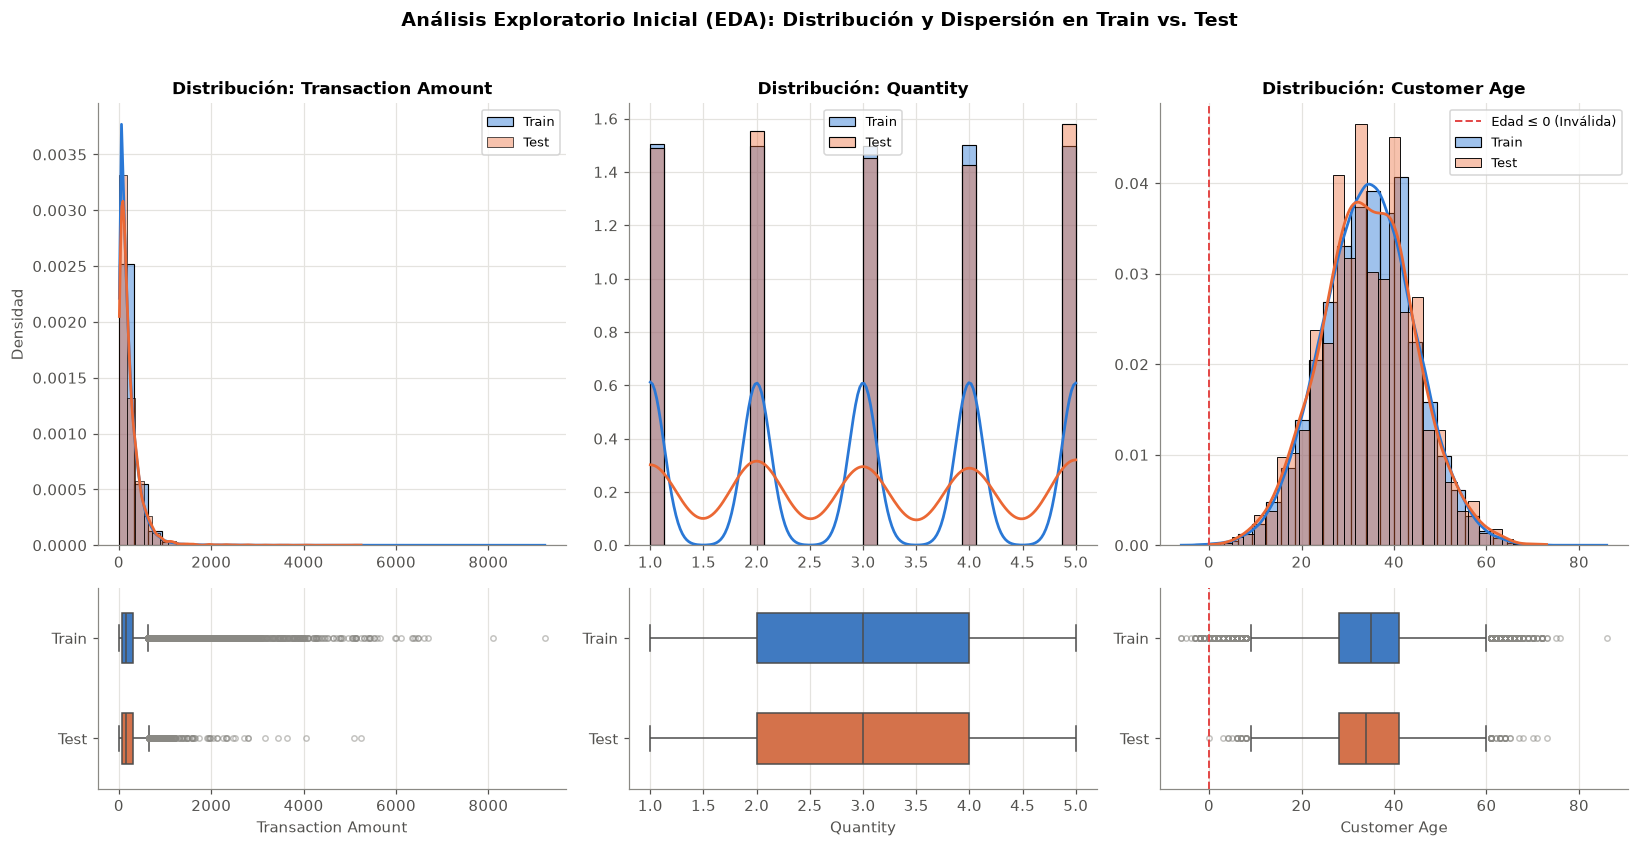

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Variables numericas a inspeccionar en el EDA
rfm_cols = ['Transaction Amount', 'Quantity', 'Customer Age']

# Construir DataFrame con métricas 
stats_df = pd.DataFrame(index=rfm_cols)

stats_df['Muestras'] = df_train[rfm_cols].count()
stats_df['Media'] = df_train[rfm_cols].mean()
stats_df['Desv. Est.'] = df_train[rfm_cols].std()
stats_df['Mínimo'] = df_train[rfm_cols].min()
stats_df['P25 (Q1)'] = df_train[rfm_cols].quantile(0.25)
stats_df['Mediana (P50)'] = df_train[rfm_cols].median()
stats_df['P75 (Q3)'] = df_train[rfm_cols].quantile(0.75)
stats_df['P95'] = df_train[rfm_cols].quantile(0.95)
stats_df['P99'] = df_train[rfm_cols].quantile(0.99)
stats_df['Máximo'] = df_train[rfm_cols].max()
stats_df['Asimetría (Skew)'] = df_train[rfm_cols].skew()
stats_df['Curtosis'] = df_train[rfm_cols].kurt()

# Estadistica para dataset de entrenamiento
titulo("Estadísticas Descriptivas y Métricas de Asimetría (Dataset Train)")
show_table(
    stats_df, 
    fmt={
        'Muestras': '.0f',
        'Media': '.2f',
        'Desv. Est.': '.2f',
        'Mínimo': '.2f',
        'P25 (Q1)': '.2f',
        'Mediana (P50)': '.2f',
        'P75 (Q3)': '.2f',
        'P95': '.2f',
        'P99': '.2f',
        'Máximo': '.2f',
        'Asimetría (Skew)': '.3f',
        'Curtosis': '.3f'
    },
    index=True
)
# Construir DataFrame con métricas 
stats_df_test = pd.DataFrame(index=rfm_cols)

stats_df_test['Muestras'] = df_test[rfm_cols].count()
stats_df_test['Media'] = df_test[rfm_cols].mean()
stats_df_test['Desv. Est.'] = df_test[rfm_cols].std()
stats_df_test['Mínimo'] = df_test[rfm_cols].min()
stats_df_test['P25 (Q1)'] = df_test[rfm_cols].quantile(0.25)
stats_df_test['Mediana (P50)'] = df_test[rfm_cols].median()
stats_df_test['P75 (Q3)'] = df_test[rfm_cols].quantile(0.75)
stats_df_test['P95'] = df_test[rfm_cols].quantile(0.95)
stats_df_test['P99'] = df_test[rfm_cols].quantile(0.99)
stats_df_test['Máximo'] = df_test[rfm_cols].max()
stats_df_test['Asimetría (Skew)'] = df_test[rfm_cols].skew()
stats_df_test['Curtosis'] = df_test[rfm_cols].kurt()

# Estadistica para dataset de entrenamiento
titulo("\nEstadísticas Descriptivas y Métricas de Asimetría (Dataset Test)")
show_table(
    stats_df_test, 
    fmt={
        'Muestras': '.0f',
        'Media': '.2f',
        'Desv. Est.': '.2f',
        'Mínimo': '.2f',
        'P25 (Q1)': '.2f',
        'Mediana (P50)': '.2f',
        'P75 (Q3)': '.2f',
        'P95': '.2f',
        'P99': '.2f',
        'Máximo': '.2f',
        'Asimetría (Skew)': '.3f',
        'Curtosis': '.3f'
    },
    index=True
)

# Figura combinada: Fila 1 = Distribuciones (Hist + KDE), Fila 2 = Boxplots comparativos
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), gridspec_kw={'height_ratios': [2.2, 1]})

for idx, col in enumerate(rfm_cols):
    ax_hist = axes[0, idx]
    ax_box = axes[1, idx]
    
    sns.histplot(
        df_train[col], bins=30, stat='density', kde=True,
        color=PALETTE[0], alpha=0.45, label='Train', ax=ax_hist
    )
    sns.histplot(
        df_test[col], bins=30, stat='density', kde=True,
        color=PALETTE[1], alpha=0.40, label='Test', ax=ax_hist
    )

    if col == 'Customer Age':
        ax_hist.axvline(0, color=PALETTE[7], linestyle='--', linewidth=1.3, label='Edad ≤ 0 (Inválida)')
        
    ax_hist.set_title(f'Distribución: {col}')
    ax_hist.set_xlabel('')
    ax_hist.set_ylabel('Densidad' if idx == 0 else '')
    ax_hist.legend(frameon=True, facecolor='white', fontsize=8.5)
    
    df_comp = pd.concat([
        pd.DataFrame({'Valor': df_train[col], 'Conjunto': 'Train'}),
        pd.DataFrame({'Valor': df_test[col], 'Conjunto': 'Test'})
    ], ignore_index=True)
    
    sns.boxplot(
        data=df_comp, x='Valor', y='Conjunto',
        palette=[PALETTE[0], PALETTE[1]], width=0.5,
        flierprops=dict(marker='o', markersize=3.5, alpha=0.5, markeredgecolor=GRIS),
        ax=ax_box
    )
    
    if col == 'Customer Age':
        ax_box.axvline(0, color=PALETTE[7], linestyle='--', linewidth=1.3)
        
    ax_box.set_xlabel(col)
    ax_box.set_ylabel('')

plt.suptitle('Análisis Exploratorio Inicial (EDA): Distribución y Dispersión en Train vs. Test', fontweight='bold', fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

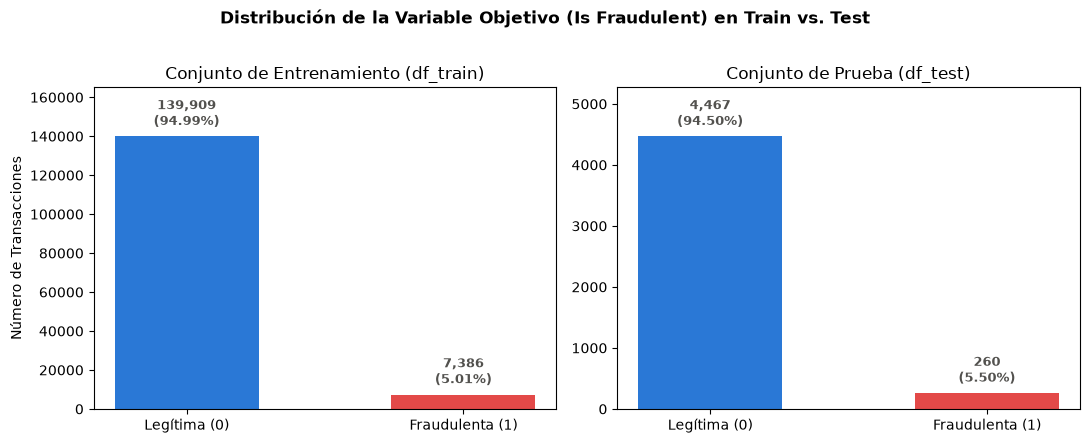

In [20]:
# Graficar balanceo de clases legitimo y fraude 
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=False)

datasets = [('Conjunto de Entrenamiento (df_train)', df_train), ('Conjunto de Prueba (df_test)', df_test)]
etiquetas_clase = ['Legítima (0)', 'Fraudulenta (1)']
colores_clase = [PALETTE[0], PALETTE[7]]

for ax, (nombre_ds, df_actual) in zip(axes, datasets):
    conteos = df_actual['Is Fraudulent'].value_counts().reindex([0, 1], fill_value=0)
    total = len(df_actual)
    porcentajes = (conteos / total) * 100
    
    barras = ax.bar(etiquetas_clase, conteos.values, color=colores_clase, width=0.52, edgecolor='none')
    
    # Anotar conteo absoluto 
    for barra, cnt, pct in zip(barras, conteos.values, porcentajes.values):
        ax.annotate(
            f'{cnt:,}\n({pct:.2f}%)',
            xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
            xytext=(0, 5),
            textcoords='offset points',
            ha='center', va='bottom',
            fontsize=9.5, fontweight='bold', color='#52514e'
        )
        
    ax.set_title(nombre_ds)
    ax.set_ylabel('Número de Transacciones' if ax == axes[0] else '')
    ax.set_ylim(0, conteos.max() * 1.18)

plt.suptitle('Distribución de la Variable Objetivo (Is Fraudulent) en Train vs. Test', fontweight='bold', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Verificar cuántos registros se eliminan y si guardan relación con el fraude al eliminar edad < 1
invalidos_train = df_train[df_train['Customer Age'] < 1]
invalidos_test = df_test[df_test['Customer Age'] < 1]

print(f"Train - Registros con edad < 1: {len(invalidos_train)} ({len(invalidos_train)/len(df_train)*100:.3f}%) | Tasa fraude: {invalidos_train['Is Fraudulent'].mean()*100:.2f}%")
print(f"Test  - Registros con edad < 1: {len(invalidos_test)} ({len(invalidos_test)/len(df_test)*100:.3f}%) | Tasa fraude: {invalidos_test['Is Fraudulent'].mean()*100:.2f}%")

# Aplicar limpieza conservando el resto de variables intactas
df_train_clean = df_train[df_train['Customer Age'] >= 1].copy()
df_test_clean = df_test[df_test['Customer Age'] >= 1].copy()

Train - Registros con edad < 1: 51 (0.035%) | Tasa fraude: 1.96%
Test  - Registros con edad < 1: 1 (0.021%) | Tasa fraude: 0.00%


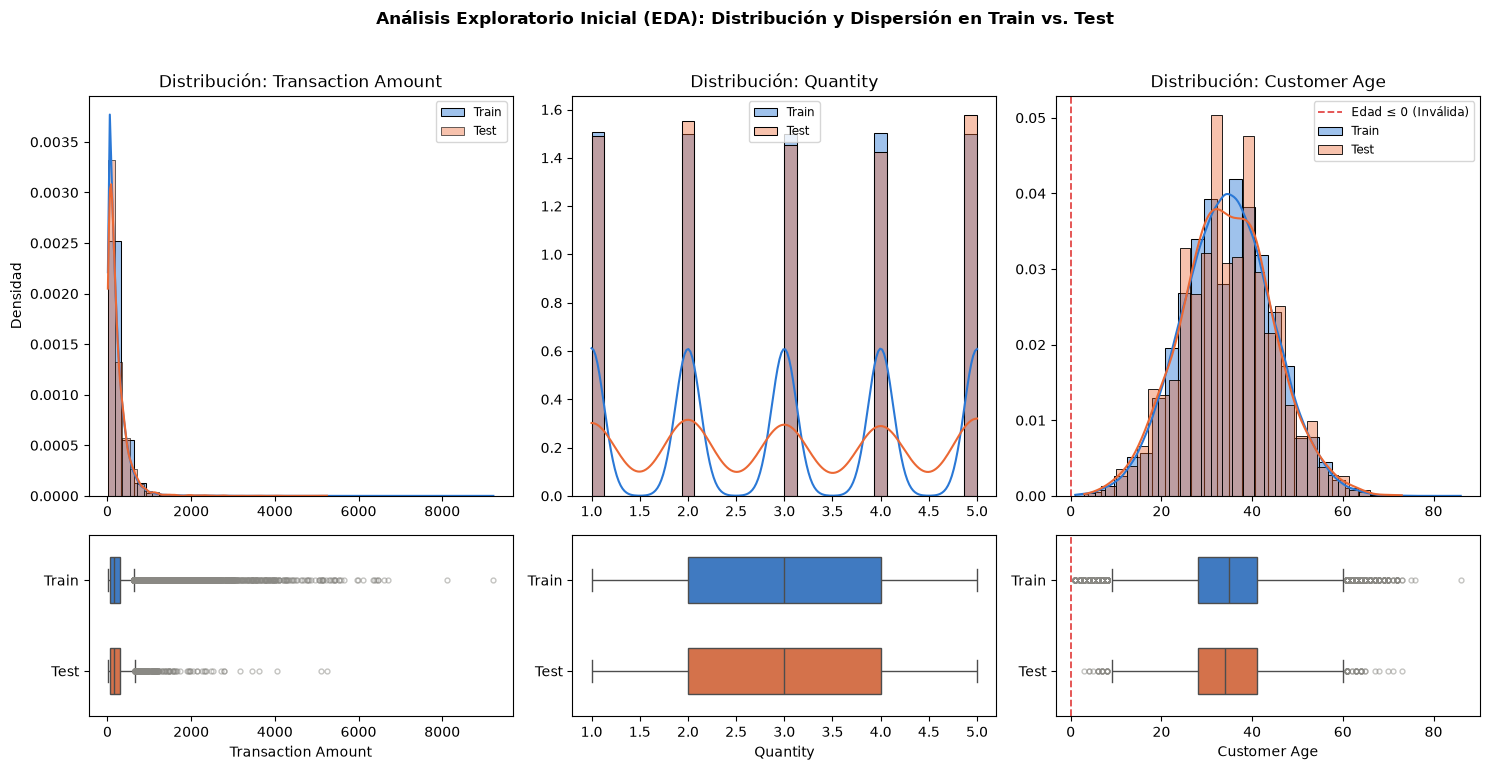

In [ ]:
# Variables numéricas a inspeccionar en el EDA depues de limpiar edad
vars_eda = ['Transaction Amount', 'Quantity', 'Customer Age']

# Figura combinada
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), gridspec_kw={'height_ratios': [2.2, 1]})

for idx, col in enumerate(vars_eda):
    ax_hist = axes[0, idx]
    ax_box = axes[1, idx]
    
    
    sns.histplot(
        df_train_clean[col], bins=30, stat='density', kde=True,
        color=PALETTE[0], alpha=0.45, label='Train', ax=ax_hist
    )
    sns.histplot(
        df_test_clean[col], bins=30, stat='density', kde=True,
        color=PALETTE[1], alpha=0.40, label='Test', ax=ax_hist
    )
    
    if col == 'Customer Age':
        ax_hist.axvline(0, color=PALETTE[7], linestyle='--', linewidth=1.3, label='Edad ≤ 0 (Inválida)')
        
    ax_hist.set_title(f'Distribución: {col}')
    ax_hist.set_xlabel('')
    ax_hist.set_ylabel('Densidad' if idx == 0 else '')
    ax_hist.legend(frameon=True, facecolor='white', fontsize=8.5)
    
    df_comp = pd.concat([
        pd.DataFrame({'Valor': df_train_clean[col], 'Conjunto': 'Train'}),
        pd.DataFrame({'Valor': df_test_clean[col], 'Conjunto': 'Test'})
    ], ignore_index=True)
    
    sns.boxplot(
        data=df_comp, x='Valor', y='Conjunto',
        palette=[PALETTE[0], PALETTE[1]], width=0.5,
        flierprops=dict(marker='o', markersize=3.5, alpha=0.5, markeredgecolor=GRIS),
        ax=ax_box
    )
    
    if col == 'Customer Age':
        ax_box.axvline(0, color=PALETTE[7], linestyle='--', linewidth=1.3)
        
    ax_box.set_xlabel(col)
    ax_box.set_ylabel('')

plt.suptitle('Análisis Exploratorio Inicial (EDA): Distribución y Dispersión en Train vs. Test', fontweight='bold', fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

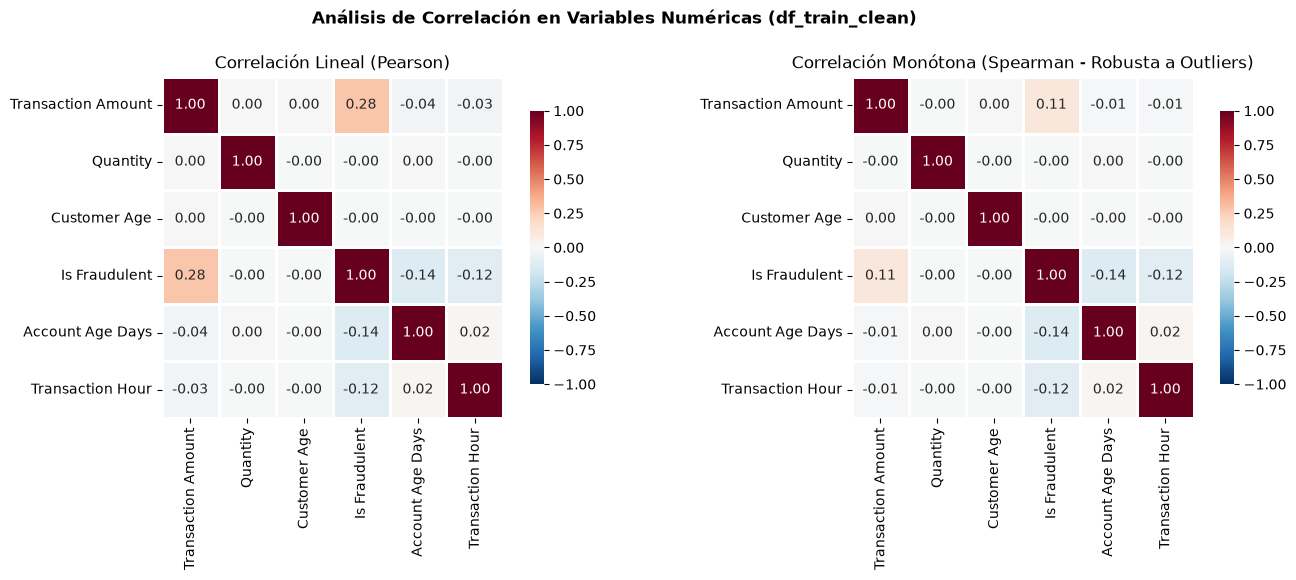

In [ ]:
# Seleccionar variables numéricas relevantes  para la matriz
cols_num = df_train_clean.select_dtypes(include=[np.number]).columns.tolist()

corr_pearson = df_train_clean[cols_num].corr(method='pearson')
corr_spearman = df_train_clean[cols_num].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(
    corr_pearson, annot=True, fmt='.2f', cmap='RdBu_r',
    vmin=-1, vmax=1, center=0, square=True, linewidths=0.8,
    cbar_kws={'shrink': 0.8}, ax=axes[0]
)
axes[0].set_title('Correlación Lineal (Pearson)')

sns.heatmap(
    corr_spearman, annot=True, fmt='.2f', cmap='RdBu_r',
    vmin=-1, vmax=1, center=0, square=True, linewidths=0.8,
    cbar_kws={'shrink': 0.8}, ax=axes[1]
)
axes[1].set_title('Correlación Monótona (Spearman - Robusta a Outliers)')

plt.suptitle('Análisis de Correlación en Variables Numéricas (df_train_clean)', fontweight='bold', fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Verificar si hay filas duplicadas 
def auditar_duplicados(df_tr, df_te):
    cols_sin_id = [c for c in df_tr.columns if c != 'Transaction ID']
    
    # Duplicados internos en cada conjunto
    dup_exactos_tr = df_tr.duplicated().sum()
    dup_exactos_te = df_te.duplicated().sum()
    
    dup_sin_id_tr = df_tr.duplicated(subset=cols_sin_id).sum()
    dup_sin_id_te = df_te.duplicated(subset=cols_sin_id).sum()
    
    dup_id_tr = df_tr.duplicated(subset=['Transaction ID']).sum()
    dup_id_te = df_te.duplicated(subset=['Transaction ID']).sum()
    
    # Solapamiento entre Train y Test (fuga de datos)
    ids_comunes = len(set(df_tr['Transaction ID']).intersection(set(df_te['Transaction ID'])))
    
    filas_tr_sin_id = set(map(tuple, df_tr[cols_sin_id].to_numpy()))
    filas_te_sin_id = set(map(tuple, df_te[cols_sin_id].to_numpy()))
    solapamiento_contenido = len(filas_tr_sin_id.intersection(filas_te_sin_id))
    
    resumen = pd.DataFrame([
        {
            'Tipo de Verificación': 'Filas 100% idénticas (todas las columnas)',
            'df_train_clean': dup_exactos_tr,
            'df_test_clean': dup_exactos_te
        },
        {
            'Tipo de Verificación': 'Filas idénticas excluyendo Transaction ID',
            'df_train_clean': dup_sin_id_tr,
            'df_test_clean': dup_sin_id_te
        },
        {
            'Tipo de Verificación': 'Transaction ID repetidos',
            'df_train_clean': dup_id_tr,
            'df_test_clean': dup_id_te
        },
        {
            'Tipo de Verificación': 'Solapamiento Train vs. Test (por Transaction ID)',
            'df_train_clean': ids_comunes,
            'df_test_clean': ids_comunes
        },
        {
            'Tipo de Verificación': 'Solapamiento Train vs. Test (por contenido sin ID)',
            'df_train_clean': solapamiento_contenido,
            'df_test_clean': solapamiento_contenido
        }
    ])
    
    titulo("Auditoría de Filas Idénticas y Solapamiento entre Particiones")
    show_table(resumen, fmt={'df_train_clean': '.0f', 'df_test_clean': '.0f'}, index=False)
    
    # Si llegan a existir filas identicas sin ID, mostrar una muestra para inspeccionarlas
    if dup_sin_id_tr > 0:
        titulo("Muestra de filas idénticas en Train (excluyendo Transaction ID)")
        muestra = df_tr[df_tr.duplicated(subset=cols_sin_id, keep=False)].sort_values(by=cols_sin_id).head(6)
        show_table(muestra, index=False)

# Ejecutar 
auditar_duplicados(df_train_clean, df_test_clean)

Tipo de Verificación,df_train_clean,df_test_clean
Filas 100% idénticas (todas las columnas),0,0
Filas idénticas excluyendo Transaction ID,0,0
Transaction ID repetidos,0,0
Solapamiento Train vs. Test (por Transaction ID),0,0
Solapamiento Train vs. Test (por contenido sin ID),0,0


#### RESPUESTA:

### Análisis Exploratorio de Datos (EDA): Calidad, Distribuciones y Correlaciones Análisis de la salida

1. **Integridad y balanceo de clases**: Tanto el conjunto de entrenamiento ($filas = 147.295$) como el de prueba ($filas = 4.727$) registran cero valores nulos, cero filas duplicadas exactas y cero solapamiento entre particiones. La variable objetivo (`Is Fraudulent`) evidencia un desbalanceo marcado propio de transacciones financieras, manteniendo proporciones equivalentes en ambas particiones: en entrenamiento el $94,99\%$ corresponde a operaciones legítimas ($139.909$) y el $5,01\%$ a fraude ($7.386$), mientras que en prueba el $94,50\%$ son legítimas ($4.467$) y el $5,50\%$ fraudulentas ($260$). 

2. **Distribución de** `Transaction Amount`: Presenta una asimetría positiva ($6,135$ en entrenamiento y $5,703$ en prueba) y elevada curtosis ($82,566$ y $62,376$), concentrando el $75\%$ central de las transacciones por debajo de $295,60$ (mediana de $151,90$ en entrenamiento y $149,24$ en prueba) frente a una cola derecha extensa que alcanza máximos de $9.221,60$ y $5.244,05$, respectivamente. Aunque el diagrama de caja exhibe numerosos valores extremos, se conservan íntegros al constituir señales de comportamiento anómalo vinculadas al fraude. 

3. **Distribución de** `Quantity`: Muestra una distribución discreta uniforme entre $1$ y $5$ unidades (mediana de $3,00$, rango intercuartílico entre $2,00$ y $4,00$, y asimetría cercana a $0$) tanto en entrenamiento como en prueba, sin valores atípicos ni incoherencias. 

4. **Distribución y depuración de** `Customer Age`: Exhibe una distribución simétrica (asimetría de $0,004$ en entrenamiento y $0,055$ en prueba) con el $50\%$ central concentrado entre los $28$ y $41$ años (medianas de $35$ y $34$ años). Sin embargo, se detecta ruido con valores de edades mínimas de $-6$ años en entrenamiento y $0$ años en prueba. Al retirar los registros con edad menor a $1$ año ($51$ filas en entrenamiento, equivalentes al $0,035\%$, y $1$ fila en prueba, equivalente al $0,021\%$), se depura el error sin afectar la representatividad de la clase fraude.  

5. **Relaciones en la matriz de correlación**: La evaluación sobre el conjunto de datos confirma ausencia de multicolinealidad entre las variables predictoras. Respecto a la clase objetivo (`Is Fraudulent`), `Transaction Amount` registra la mayor asociación positiva ($r = 0,28$ en Pearson y $\rho = 0,11$ en Spearman), seguida por asociaciones inversas leves con `Account Age Days` ($-0,14$) y `Transaction Hour` ($-0,12$), lo que indica que las operaciones fraudulentas tienden a concentrarse en montos elevados, cuentas recientes y franjas horarias específicas.  

La exploración confirma particiones limpias y consistentes en su proporción de fraude ($\approx 5\%$), destacando `Transaction Amount` como la variable numérica con mayor capacidad discriminativa individual, aunque con correlaciones lineales moderadas que exigen capturar interacciones multivariantes y contextuales. 

Se fija como base de modelado el subconjunto depurado (`Customer Age` $>= 1$), conservando sin recortes las colas extremas de `Transaction Amount` y aplicando escalado robusto junto con ingeniería de variables contextuales y colectivas antes de entrenar los detectores no supervisados.

#### PREGUNTA 2:
* Aplica los preprocesamientos iniciales en los datos

#### RESPUESTA:


## 3. Detección de anomalías puntuales


#### PREGUNTA 3:
* Considerando 'Transaction Amount' como variable para tratar de predecir el fraude desde ella, aplica métodos estadísticos univariantes para detección de anomalías.
* Analiza los resultados obtenidos.


#### RESPUESTA:

####

## 4. Detección de anomalías contextuales


#### PREGUNTA 4:
* Considera métodos de detección de anomalías que permitan ver anomalías contextuales de manera no supervisada, y aplícalos sobre los datos.
* Analiza los resultados obtenidos.

#### RESPUESTA:

### 5. Detección de anomalías colectivas
* Sliding window
* PELT

#### PREGUNTA 5:
* Considera ahora métodos de detección de anomalías que permitan ver anomalías colectivas de manera univariante, sobre la variable 'Transaction Amount'. Aplica estos métodos.
* Analiza los resultados obtenidos.

#### RESPUESTA: